# 04 – Federated GNN across 4 hospitals (UCI)

**Goal:** train a Graph Neural Network across 4 hospitals without sharing patient data.

- Each hospital builds its **own patient-similarity graph** (patients and links never leave the hospital)
- A GCN is trained with **Federated Averaging (FedAvg)**: only model weights are shared
- Compared with: each hospital alone (local only) and all data pooled (centralised)

## Step 1 – Load and clean the 4 hospitals

In [1]:
import warnings; warnings.filterwarnings("ignore")
import copy, numpy as np, pandas as pd, torch, torch.nn.functional as F
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

torch.manual_seed(42); np.random.seed(42)

cols = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
        "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"]
hospitals = {"Cleveland": "processed.cleveland.data", "Hungary": "processed.hungarian.data",
             "Switzerland": "processed.switzerland.data", "VA": "processed.va.data"}

frames = []
for name, file in hospitals.items():
    d = pd.read_csv(f"../data/UCI/{file}", header=None, names=cols, na_values="?")
    d["hospital"] = name
    frames.append(d)

df = pd.concat(frames, ignore_index=True)
df["target"] = (df["num"] > 0).astype(int)
df = df.drop(columns=["num", "slope", "ca", "thal"])
df.loc[df["chol"] == 0, "chol"] = np.nan
df.loc[df["trestbps"] == 0, "trestbps"] = np.nan
df = pd.get_dummies(df, columns=["cp"], prefix="cp", dtype=int)

features = [c for c in df.columns if c not in ("hospital", "target")]
print(df.shape, len(features), "features")

(920, 15) 13 features


## Step 2 – Split each hospital (70% train / 30% test)

Each hospital keeps its own split. Missing values and scaling use shared **summary statistics** only (medians, means), never patient rows.

In [2]:
data = {}
for h, g in df.groupby("hospital", sort=False):
    data[h] = train_test_split(g[features], g["target"], test_size=0.3,
                               stratify=g["target"], random_state=42)

X_train_all = pd.concat([d[0] for d in data.values()])
imputer = SimpleImputer(strategy="median").fit(X_train_all)
scaler = StandardScaler().fit(imputer.transform(X_train_all))
prep = lambda X: scaler.transform(imputer.transform(X)).astype("float32")

## Step 3 – Build one patient graph per hospital

- Each hospital links each of its patients to their **5 most similar patients in the same hospital**
- No links between hospitals: graphs stay private
- Test patients are in the graph, but their outcomes are hidden during training

In [3]:
from sklearn.neighbors import kneighbors_graph
from torch_geometric.data import Data
from torch_geometric.utils import to_undirected

K = 5

def build_hospital_graph(X_tr, X_te, y_tr, y_te):
    Z = np.vstack([prep(X_tr), prep(X_te)])
    A = kneighbors_graph(Z, n_neighbors=K, include_self=False).tocoo()
    edge_index = to_undirected(torch.tensor(np.vstack([A.row, A.col]), dtype=torch.long))
    y = torch.tensor(np.concatenate([y_tr.values, y_te.values]), dtype=torch.float)
    train_mask = torch.zeros(len(Z), dtype=torch.bool); train_mask[:len(X_tr)] = True
    return Data(x=torch.tensor(Z), edge_index=edge_index, y=y,
                train_mask=train_mask, test_mask=~train_mask)

graphs = {h: build_hospital_graph(*d) for h, d in data.items()}
for h, g in graphs.items():
    print(f"{h:12s} patients={g.num_nodes:3d}  links={g.edge_index.shape[1]}")

Cleveland    patients=303  links=2078
Hungary      patients=294  links=2068
Switzerland  patients=123  links=894
VA           patients=200  links=1430


## Step 4 – GCN model and helper functions

- **GCN** (Graph Convolutional Network): each patient's prediction combines their own data with their neighbours'
- `train_on_graph`: trains a model on one hospital's graph
- `evaluate`: AUC on each hospital's test patients + all test patients combined

In [4]:
from torch_geometric.nn import GCNConv

class GCN(torch.nn.Module):
    def __init__(self, in_dim, hidden=16):
        super().__init__()
        self.conv1 = GCNConv(in_dim, hidden)
        self.conv2 = GCNConv(hidden, 1)
    def forward(self, x, edge_index):
        x = F.dropout(x, 0.3, self.training)
        x = F.relu(self.conv1(x, edge_index))
        x = F.dropout(x, 0.3, self.training)
        return self.conv2(x, edge_index).squeeze(-1)

def train_on_graph(model, g, epochs, lr=0.01):
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=5e-4)
    for _ in range(epochs):
        model.train(); opt.zero_grad()
        out = model(g.x, g.edge_index)
        loss = F.binary_cross_entropy_with_logits(out[g.train_mask], g.y[g.train_mask])
        loss.backward(); opt.step()
    return model

def evaluate(model_or_models):
    scores, all_p, all_y = {}, [], []
    for h, g in graphs.items():
        m = model_or_models[h] if isinstance(model_or_models, dict) else model_or_models
        m.eval()
        with torch.no_grad():
            p = torch.sigmoid(m(g.x, g.edge_index))[g.test_mask]
        y = g.y[g.test_mask]
        scores[h] = roc_auc_score(y, p); all_p.append(p); all_y.append(y)
    scores["ALL (combined test)"] = roc_auc_score(torch.cat(all_y), torch.cat(all_p))
    return scores

n_features = len(features)

## Step 5 – Local only (each hospital trains alone)

In [5]:
torch.manual_seed(42)
local_models = {h: train_on_graph(GCN(n_features), g, epochs=200) for h, g in graphs.items()}
r_local = evaluate(local_models)
{k: round(v, 3) for k, v in r_local.items()}

{'Cleveland': 0.861,
 'Hungary': 0.888,
 'Switzerland': 0.586,
 'VA': 0.627,
 'ALL (combined test)': 0.873}

## Step 6 – Centralised (one model trained on all 4 hospital graphs together)

This is the upper benchmark – but it requires pooling patient data, which privacy rules forbid.

In [6]:
torch.manual_seed(42)
central = GCN(n_features)
opt = torch.optim.Adam(central.parameters(), lr=0.01, weight_decay=5e-4)
n_train_total = sum(int(g.train_mask.sum()) for g in graphs.values())

for epoch in range(200):
    central.train(); opt.zero_grad()
    loss = sum(F.binary_cross_entropy_with_logits(central(g.x, g.edge_index)[g.train_mask],
                                                  g.y[g.train_mask], reduction="sum")
               for g in graphs.values()) / n_train_total
    loss.backward(); opt.step()

r_central = evaluate(central)
{k: round(v, 3) for k, v in r_central.items()}

{'Cleveland': 0.871,
 'Hungary': 0.879,
 'Switzerland': 0.286,
 'VA': 0.744,
 'ALL (combined test)': 0.872}

## Step 7 – Federated GNN (FedAvg)

Each round:
1. Server sends the global GCN to all 4 hospitals
2. Each hospital trains it for 5 epochs **on its own private graph**
3. Hospitals send back **only the model weights**
4. Server averages the weights (weighted by hospital size)

40 rounds in total.

In [7]:
torch.manual_seed(42)
global_model = GCN(n_features)
sizes = {h: int(g.train_mask.sum()) for h, g in graphs.items()}
history = []

for rnd in range(1, 41):
    updates = []
    for h, g in graphs.items():
        local_copy = copy.deepcopy(global_model)          # hospital receives global model
        train_on_graph(local_copy, g, epochs=5)           # trains on its own graph
        updates.append((local_copy.state_dict(), sizes[h]))  # sends back weights only

    # Server: weighted average of all weights
    new_weights = {k: sum(state[k] * n for state, n in updates) / n_train_total
                   for k in updates[0][0]}
    global_model.load_state_dict(new_weights)
    history.append({"round": rnd, "AUC": evaluate(global_model)["ALL (combined test)"]})

history = pd.DataFrame(history)
history.iloc[[0, 9, 19, 39]].round(3)

,round,AUC
0,1,0.730
9,10,0.872
19,20,0.873
39,40,0.874


## Step 8 – Learning curve

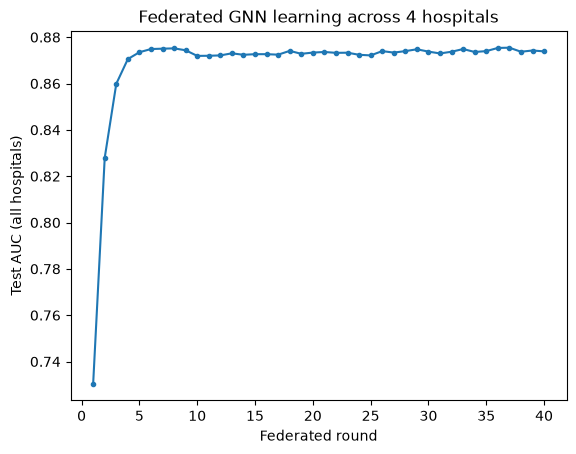

In [8]:
import matplotlib.pyplot as plt

plt.plot(history["round"], history["AUC"], "o-", markersize=3)
plt.xlabel("Federated round"); plt.ylabel("Test AUC (all hospitals)")
plt.title("Federated GNN learning across 4 hospitals")
plt.savefig("../outputs/federated_gnn_learning_curve.png", dpi=150, bbox_inches="tight")
plt.show()

## Step 9 – Compare local, centralised and federated

In [9]:
pd.DataFrame({"local_only": r_local, "centralised": r_central, "federated": r_fed
              if (r_fed := evaluate(global_model)) else None}).round(3)

,local_only,centralised,federated
Cleveland,0.861,0.871,0.864
Hungary,0.888,0.879,0.879
Switzerland,0.586,0.286,0.129
VA,0.627,0.744,0.791
ALL (combined test),0.873,0.872,0.874


## Summary

| Model | Setting | AUC (all test patients) |
|---|---|---|
| Logistic Regression | Federated (notebook 02) | 0.881 |
| GCN | Local only | 0.873 |
| GCN | Centralised | 0.872 |
| **GCN** | **Federated** | **0.874** |

- The **federated GNN matches centralised training** (0.874 vs 0.872), with each hospital's patients and graph staying private
- **VA benefits most** from federation: 0.63 alone → 0.79 federated
- Overall the GNN performs on par with federated logistic regression (0.874 vs 0.881), consistent with the Framingham finding (notebook 03)
- Switzerland excluded from interpretation (only 2 healthy patients in its test set)